<a href="https://colab.research.google.com/github/XxTurahPlayz/lingoguard-ai/blob/main/LingoGuard_AI_Hackathon_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
print("LingoGuard AI — Project Started!")
print("Track: AI + Languages")
print("Focus: Indonesian, Malay, English, Spanish and French")

LingoGuard AI — Project Started!
Track: AI + Languages
Focus: Indonesian, Malay, English, Spanish and French


In [55]:
!pip -q install pandas scikit-learn matplotlib seaborn langdetect gradio joblib

In [56]:
import tarfile

archive = "/content/sentences.tar.bz2"

with tarfile.open(archive, "r:bz2") as tar:
    for item in tar.getmembers():
        print(item.name)

sentences.csv


In [57]:
import tarfile
import os

archive = "/content/sentences.tar.bz2"

with tarfile.open(archive, "r:bz2") as tar:
    file = tar.extractfile("sentences.csv")
    with open("/content/sentences.csv", "wb") as output:
        output.write(file.read())

print("Dataset extracted successfully!")
print("File exists:", os.path.exists("/content/sentences.csv"))

Dataset extracted successfully!
File exists: True


In [58]:
import csv

with open("/content/sentences.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file, delimiter="\t")

    for i, row in enumerate(reader):
        print(row)
        if i == 4:
            break


['1', 'cmn', '我們試試看！']
['2', 'cmn', '我该去睡觉了。']
['3', 'cmn', '你在干什麼啊？']
['4', 'cmn', '這是什麼啊？']
['5', 'cmn', '今天是６月１８号，也是Muiriel的生日！']


In [59]:
from collections import Counter
import csv

language_counts = Counter()

with open("/content/sentences.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file, delimiter="\t")

    for row in reader:
        if len(row) == 3 and row[1] in ["ind", "msa", "eng", "spa", "fra"]:
            language_counts[row[1]] += 1

for language, count in language_counts.items():
    print(language, ":", count, "sentences")

fra : 729867 sentences
eng : 2038609 sentences
spa : 442846 sentences
ind : 28406 sentences


In [60]:
import csv
from collections import Counter

counts = Counter()

with open("/content/sentences.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file, delimiter="\t")

    for row in reader:
        if len(row) == 3 and row[1].startswith("ms"):
            counts[row[1]] += 1

print(counts)

Counter()


In [61]:
import csv
from collections import Counter

target_languages = ["ind", "eng", "spa", "fra"]
counts = Counter()

with open("/content/sentences.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file, delimiter="\t")

    for row in reader:
        if len(row) == 3 and row[1] in target_languages:
            counts[row[1]] += 1

for lang in target_languages:
    print(f"{lang}: {counts[lang]:,}")

ind: 28,406
eng: 2,038,609
spa: 442,846
fra: 729,867


In [62]:
import csv
import random
import pandas as pd

random.seed(42)

target_languages = ["ind", "eng", "spa", "fra"]
sentences = {lang: [] for lang in target_languages}

with open("/content/sentences.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file, delimiter="\t")

    for row in reader:
        if len(row) != 3:
            continue

        sentence_id, language, text = row

        if language in target_languages and len(sentences[language]) < 2000:
            if text.strip():
                sentences[language].append(text.strip())

data = []

for lang, examples in sentences.items():
    for sentence in examples:
        data.append({"text": sentence, "language": lang})

df = pd.DataFrame(data)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df["language"].value_counts())
print("\nTotal sentences:", len(df))
print("\nSample sentences:")
print(df.head())

language
eng    2000
ind    2000
spa    2000
fra    2000
Name: count, dtype: int64

Total sentences: 8000

Sample sentences:
                                                text language
0  I wish I could care more about my grades but i...      eng
1                       We went to London last year.      eng
2                          Ini pertanyaan yang bagus      ind
3                             Like father, like son.      eng
4                                      ¿Qué hora es?      spa


In [63]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate sentences:")
print(df["text"].duplicated().sum())

print("\nDataset information:")
print(df.info())

Missing values:
text        0
language    0
dtype: int64

Duplicate sentences:
0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      8000 non-null   object
 1   language  8000 non-null   object
dtypes: object(2)
memory usage: 125.1+ KB
None


In [64]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["language"]

# First: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second: split temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 5600
Validation samples: 1200
Testing samples: 1200


In [65]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(1, 3),
    min_df=2,
    max_features=150000,
    sublinear_tf=True
)

X_train_features = vectorizer.fit_transform(X_train)
X_val_features = vectorizer.transform(X_val)
X_test_features = vectorizer.transform(X_test)

print("Training feature shape:", X_train_features.shape)
print("Validation feature shape:", X_val_features.shape)
print("Testing feature shape:", X_test_features.shape)

Training feature shape: (5600, 7294)
Validation feature shape: (1200, 7294)
Testing feature shape: (1200, 7294)


In [66]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_features, y_train)

print("LingoGuard AI model trained successfully!")
print("Number of language classes:", len(model.classes_))
print("Languages:", model.classes_)


LingoGuard AI model trained successfully!
Number of language classes: 4
Languages: ['eng' 'fra' 'ind' 'spa']


In [67]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_features)

accuracy = accuracy_score(y_test, y_pred)

print("LingoGuard AI Test Accuracy:")
print(f"{accuracy * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))


LingoGuard AI Test Accuracy:
99.75%

Detailed Classification Report:
              precision    recall  f1-score   support

         eng       1.00      1.00      1.00       300
         fra       1.00      0.99      1.00       300
         ind       1.00      1.00      1.00       300
         spa       0.99      1.00      1.00       300

    accuracy                           1.00      1200
   macro avg       1.00      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200



In [68]:
import pandas as pd

results = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

errors = results[results["actual"] != results["predicted"]]

print("Total mistakes:", len(errors))
print("\nMisclassified sentences:")
print(errors.to_string(index=False))

Total mistakes: 3

Misclassified sentences:
                      text actual predicted
Ferme la porte en sortant.    fra       spa
    Mon nom est Hashimoto.    fra       spa
               halo dunia!    ind       spa


In [69]:
short_tests = [
    "halo",
    "halo dunia!",
    "selamat pagi",
    "bonjour",
    "merci",
    "hola",
    "buenos dias",
    "hello",
    "good morning",
    "terima kasih"
]

short_features = vectorizer.transform(short_tests)
short_predictions = model.predict(short_features)

for sentence, prediction in zip(short_tests, short_predictions):
    print(f"{sentence:20} -> {prediction}")

halo                 -> spa
halo dunia!          -> spa
selamat pagi         -> ind
bonjour              -> fra
merci                -> fra
hola                 -> spa
buenos dias          -> spa
hello                -> spa
good morning         -> eng
terima kasih         -> ind


In [70]:
import pandas as pd

short_features = vectorizer.transform(short_tests)
probabilities = model.predict_proba(short_features)

for sentence, scores in zip(short_tests, probabilities):
    ranking = sorted(
        zip(model.classes_, scores),
        key=lambda x: x[1],
        reverse=True
    )

    print(f"\nSentence: {sentence}")
    for language, score in ranking:
        print(f"  {language}: {score:.4f}")


Sentence: halo
  spa: 0.4625
  eng: 0.2387
  ind: 0.1995
  fra: 0.0993

Sentence: halo dunia!
  spa: 0.5798
  ind: 0.2285
  eng: 0.1085
  fra: 0.0833

Sentence: selamat pagi
  ind: 0.8266
  fra: 0.0877
  eng: 0.0441
  spa: 0.0416

Sentence: bonjour
  fra: 0.5533
  eng: 0.1853
  spa: 0.1484
  ind: 0.1130

Sentence: merci
  fra: 0.3686
  spa: 0.3396
  ind: 0.1742
  eng: 0.1177

Sentence: hola
  spa: 0.4024
  eng: 0.2522
  ind: 0.2215
  fra: 0.1240

Sentence: buenos dias
  spa: 0.8528
  ind: 0.0973
  fra: 0.0284
  eng: 0.0214

Sentence: hello
  spa: 0.4419
  eng: 0.3597
  fra: 0.1267
  ind: 0.0717

Sentence: good morning
  eng: 0.6677
  ind: 0.1265
  spa: 0.1237
  fra: 0.0820

Sentence: terima kasih
  ind: 0.8703
  spa: 0.0502
  eng: 0.0428
  fra: 0.0367


In [71]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

val_probabilities = model.predict_proba(X_val_features)
val_predictions = model.predict(X_val_features)

confidence = val_probabilities.max(axis=1)
correct = (val_predictions == y_val.values)

thresholds = [0.40, 0.50, 0.60, 0.70, 0.80]

rows = []

for threshold in thresholds:
    accepted = confidence >= threshold

    coverage = accepted.mean() * 100

    accuracy = (
        accuracy_score(y_val.values[accepted], val_predictions[accepted])
        if accepted.any() else 0
    )

    rows.append({
        "Threshold": threshold,
        "Accepted (%)": round(coverage, 2),
        "Accuracy of accepted (%)": round(accuracy * 100, 2)
    })

print(pd.DataFrame(rows).to_string(index=False))

 Threshold  Accepted (%)  Accuracy of accepted (%)
       0.4         99.42                     99.83
       0.5         98.83                     99.92
       0.6         97.75                    100.00
       0.7         96.00                    100.00
       0.8         88.92                    100.00


In [72]:
def predict_language(text, threshold=0.60):
    features = vectorizer.transform([text])
    scores = model.predict_proba(features)[0]

    best_index = scores.argmax()
    best_language = model.classes_[best_index]
    confidence = scores[best_index]

    if confidence < threshold:
        return "uncertain", confidence

    return best_language, confidence


for sentence in short_tests:
    language, confidence = predict_language(sentence)

    print(
        f"{sentence:20} -> "
        f"{language:10} ({confidence:.1%})"
    )

halo                 -> uncertain  (46.3%)
halo dunia!          -> uncertain  (58.0%)
selamat pagi         -> ind        (82.7%)
bonjour              -> uncertain  (55.3%)
merci                -> uncertain  (36.9%)
hola                 -> uncertain  (40.2%)
buenos dias          -> spa        (85.3%)
hello                -> uncertain  (44.2%)
good morning         -> eng        (66.8%)
terima kasih         -> ind        (87.0%)


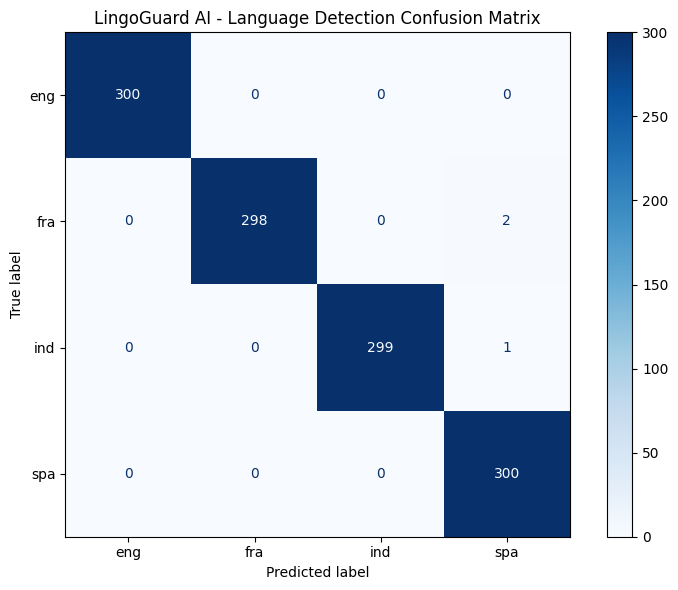

In [73]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("LingoGuard AI - Language Detection Confusion Matrix")
plt.tight_layout()
plt.show()

In [74]:
import gradio as gr

print("Gradio version:", gr.__version__)
print("LingoGuard interface setup ready!")

Gradio version: 6.31.0
LingoGuard interface setup ready!


In [75]:
def lingoguard_demo(text):
    if not text or not text.strip():
        return "Please enter a sentence first."

    features = vectorizer.transform([text])
    scores = model.predict_proba(features)[0]

    best_index = scores.argmax()
    language = model.classes_[best_index]
    score = scores[best_index]

    language_names = {
        "eng": "English",
        "fra": "French",
        "ind": "Indonesian",
        "spa": "Spanish"
    }

    if score < 0.60:
        return (
            "### ⚠️ Uncertain prediction\n"
            f"**Top candidate:** {language_names[language]}\n\n"
            f"**Model score:** {score:.1%}\n\n"
            "Please provide more text for a more reliable prediction."
        )

    return (
        "### ✅ Language detected!\n"
        f"**Language:** {language_names[language]}\n\n"
        f"**Model score:** {score:.1%}"
    )

print(lingoguard_demo("Selamat pagi!"))

### ✅ Language detected!
**Language:** Indonesian

**Model score:** 82.3%


In [76]:
import gradio as gr

app = gr.Interface(
    fn=lingoguard_demo,
    inputs=gr.Textbox(
        lines=4,
        placeholder="Type a sentence here...",
        label="Enter your text"
    ),
    outputs=gr.Markdown(label="LingoGuard Result"),
    title="🌍 LingoGuard AI",
    description=(
        "AI-powered language identification "
        "for English, French, Indonesian and Spanish."
    ),
    examples=[
        "Selamat pagi, apa kabar?",
        "Hello, how are you?",
        "Bonjour, comment allez-vous?",
        "Hola, ¿cómo estás?"
    ]
)

print("LingoGuard web app created successfully!")

LingoGuard web app created successfully!


In [77]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7b6a500353e7bd126d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [78]:
import csv
import random
import pandas as pd

random.seed(42)

target_languages = ["ind", "eng", "spa", "fra"]
sample_size = 2000

reservoirs = {lang: [] for lang in target_languages}
counts = {lang: 0 for lang in target_languages}

with open("/content/sentences.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file, delimiter="\t")

    for row in reader:
        if len(row) != 3:
            continue

        sentence_id, language, text = row
        if language not in target_languages or not text.strip():
            continue

        counts[language] += 1
        n = counts[language]

        if len(reservoirs[language]) < sample_size:
            reservoirs[language].append(text.strip())
        else:
            j = random.randrange(n)
            if j < sample_size:
                reservoirs[language][j] = text.strip()

data = []

for lang in target_languages:
    for sentence in reservoirs[lang]:
        data.append({"text": sentence, "language": lang})

df = pd.DataFrame(data).sample(
    frac=1, random_state=42
).reset_index(drop=True)

print(df["language"].value_counts())
print("\nTotal sentences:", len(df))

language
eng    2000
ind    2000
spa    2000
fra    2000
Name: count, dtype: int64

Total sentences: 8000


In [79]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["language"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 5600
Validation: 1200
Testing: 1200


In [80]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Extract character patterns
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(1, 3),
    min_df=2,
    max_features=150000,
    sublinear_tf=True
)

X_train_features = vectorizer.fit_transform(X_train)

# Transform validation and testing data
X_val_features = vectorizer.transform(X_val)
X_test_features = vectorizer.transform(X_test)

# Train the new model
model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_features, y_train)

print("New LingoGuard model trained successfully!")
print("Features:", X_train_features.shape[1])
print("Languages:", model.classes_)

New LingoGuard model trained successfully!
Features: 7182
Languages: ['eng' 'fra' 'ind' 'spa']


In [81]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_features)

accuracy = accuracy_score(y_test, y_pred)

print("NEW LINGOGUARD TEST ACCURACY")
print(f"{accuracy * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

NEW LINGOGUARD TEST ACCURACY
99.33%

Detailed Classification Report:
              precision    recall  f1-score   support

         eng       0.99      0.98      0.99       300
         fra       0.99      1.00      1.00       300
         ind       1.00      0.99      0.99       300
         spa       0.99      1.00      1.00       300

    accuracy                           0.99      1200
   macro avg       0.99      0.99      0.99      1200
weighted avg       0.99      0.99      0.99      1200



In [82]:
import pandas as pd

results = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

errors = results[results["actual"] != results["predicted"]]

print("Total mistakes:", len(errors))
print(errors.to_string(index=False))

Total mistakes: 8
                                   text actual predicted
                   Hewan ini herbivora.    ind       eng
                Our silence says a lot.    eng       fra
                   Silence is violence.    eng       fra
                             Tory dies.    eng       spa
                    His name eludes me.    eng       spa
           Youba habite à Tizi Gheniff.    fra       eng
Toki Pona is such a beautiful language!    eng       ind
                            halo dunia!    ind       spa


In [83]:
val_probabilities = model.predict_proba(X_val_features)
val_predictions = model.predict(X_val_features)

confidence = val_probabilities.max(axis=1)

thresholds = [0.40, 0.50, 0.60, 0.70, 0.80]

for threshold in thresholds:
    accepted = confidence >= threshold

    coverage = accepted.mean() * 100

    accuracy = (
        accuracy_score(
            y_val.values[accepted],
            val_predictions[accepted]
        ) * 100
        if accepted.any() else 0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Coverage: {coverage:.2f}% | "
        f"Accuracy: {accuracy:.2f}%"
    )

Threshold: 0.40 | Coverage: 99.58% | Accuracy: 99.75%
Threshold: 0.50 | Coverage: 98.58% | Accuracy: 99.92%
Threshold: 0.60 | Coverage: 96.50% | Accuracy: 100.00%
Threshold: 0.70 | Coverage: 92.83% | Accuracy: 100.00%
Threshold: 0.80 | Coverage: 86.08% | Accuracy: 100.00%


In [84]:
def lingoguard_demo(text):
    if not text or not text.strip():
        return "Please enter a sentence first."

    features = vectorizer.transform([text])
    scores = model.predict_proba(features)[0]

    best_index = scores.argmax()
    language = model.classes_[best_index]
    score = scores[best_index]

    language_names = {
        "eng": "English",
        "fra": "French",
        "ind": "Indonesian",
        "spa": "Spanish"
    }

    if score < 0.60:
        return (
            "### ⚠️ Uncertain prediction\n"
            f"**Top candidate:** {language_names[language]}\n\n"
            f"**Model score:** {score:.1%}\n\n"
            "Please provide more text for a more reliable prediction."
        )

    return (
        "### ✅ Language detected!\n"
        f"**Language:** {language_names[language]}\n\n"
        f"**Model score:** {score:.1%}"
    )

print(lingoguard_demo("halo dunia!"))

### ⚠️ Uncertain prediction
**Top candidate:** Spanish

**Model score:** 53.5%

Please provide more text for a more reliable prediction.


In [85]:
# Close the previous interface if it is running
try:
    app.close()
except:
    pass

# Create the updated interface
app = gr.Interface(
    fn=lingoguard_demo,
    inputs=gr.Textbox(
        lines=4,
        placeholder="Type a sentence here...",
        label="Enter your text"
    ),
    outputs=gr.Markdown(),
    title="🌍 LingoGuard AI",
    description=(
        "Multilingual AI language identification "
        "with uncertainty detection."
    ),
    examples=[
        "Selamat pagi, apa kabar?",
        "Hello, how are you?",
        "Bonjour, comment allez-vous?",
        "Hola, ¿cómo estás?",
        "halo dunia!"
    ]
)

print("Updated LingoGuard interface is ready!")

Closing server running on port: 7861
Updated LingoGuard interface is ready!


In [86]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f6cf044eec5c8c0886.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [87]:
test_sentences = [
    "Selamat pagi, apa kabar?",
    "Hello, how are you?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?",
    "halo dunia!"
]

for sentence in test_sentences:
    print("Input:", sentence)
    print(lingoguard_demo(sentence))
    print("-" * 40)

Input: Selamat pagi, apa kabar?
### ✅ Language detected!
**Language:** Indonesian

**Model score:** 89.7%
----------------------------------------
Input: Hello, how are you?
### ✅ Language detected!
**Language:** English

**Model score:** 92.0%
----------------------------------------
Input: Bonjour, comment allez-vous?
### ✅ Language detected!
**Language:** French

**Model score:** 92.0%
----------------------------------------
Input: Hola, ¿cómo estás?
### ✅ Language detected!
**Language:** Spanish

**Model score:** 95.4%
----------------------------------------
Input: halo dunia!
### ⚠️ Uncertain prediction
**Top candidate:** Spanish

**Model score:** 53.5%

Please provide more text for a more reliable prediction.
----------------------------------------


In [88]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("MAJORITY BASELINE")
print("Accuracy:", accuracy_score(y_test, baseline_predictions))
print("Macro F1:", f1_score(
    y_test, baseline_predictions, average="macro"
))

MAJORITY BASELINE
Accuracy: 0.25
Macro F1: 0.1


In [90]:
from langdetect import detect, LangDetectException
from sklearn.metrics import accuracy_score, f1_score

language_map = {
    "en": "eng",
    "fr": "fra",
    "id": "ind",
    "es": "spa"
}

def detect_language(text):
    try:
        detected = detect(text)
        return language_map.get(detected, "unsupported")
    except LangDetectException:
        return "unsupported"

langdetect_predictions = [
    detect_language(text) for text in X_test_text
]

print("langdetect accuracy:",
      accuracy_score(y_test, langdetect_predictions))

print("langdetect macro F1:",
      f1_score(
          y_test,
          langdetect_predictions,
          labels=["eng", "fra", "ind", "spa"],
          average="macro",
          zero_division=0
      ))

NameError: name 'X_test_text' is not defined

In [91]:
print("X_test type:", type(X_test))
print("First test example:", X_test[0])
print("y_test first example:", y_test[0])

X_test type: <class 'pandas.core.series.Series'>


KeyError: 0

In [92]:
print("First test sentence:", X_test.iloc[0])
print("First actual language:", y_test.iloc[0])
print("Number of test sentences:", len(X_test))

First test sentence: Aku ingin tahu apakah itu benar.
First actual language: ind
Number of test sentences: 1200


In [93]:
from langdetect import detect, LangDetectException
from sklearn.metrics import accuracy_score, f1_score

language_map = {
    "en": "eng",
    "fr": "fra",
    "id": "ind",
    "es": "spa"
}

def detect_language(text):
    try:
        detected = detect(str(text))
        return language_map.get(detected, "unsupported")
    except LangDetectException:
        return "unsupported"

langdetect_predictions = [
    detect_language(text) for text in X_test
]

print("LANGDETECT BASELINE")
print("Accuracy:", accuracy_score(y_test, langdetect_predictions))
print("Macro F1:", f1_score(
    y_test,
    langdetect_predictions,
    labels=["eng", "fra", "ind", "spa"],
    average="macro",
    zero_division=0
))

LANGDETECT BASELINE
Accuracy: 0.9183333333333333
Macro F1: 0.9514792858830211


In [94]:
from sklearn.metrics import f1_score

lingoguard_predictions = model.predict(vectorizer.transform(X_test))

print("LingoGuard accuracy:",
      accuracy_score(y_test, lingoguard_predictions))

print("LingoGuard macro F1:",
      f1_score(y_test, lingoguard_predictions, average="macro"))

LingoGuard accuracy: 0.9933333333333333
LingoGuard macro F1: 0.9933248886779268


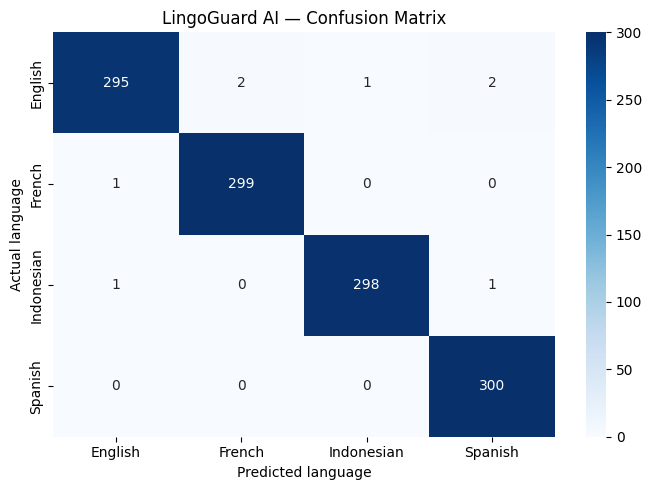

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    lingoguard_predictions,
    labels=["eng", "fra", "ind", "spa"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["English", "French", "Indonesian", "Spanish"],
    yticklabels=["English", "French", "Indonesian", "Spanish"]
)

plt.xlabel("Predicted language")
plt.ylabel("Actual language")
plt.title("LingoGuard AI — Confusion Matrix")
plt.tight_layout()
plt.show()

In [96]:
import pandas as pd

error_analysis = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(lingoguard_predictions)
})

errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
]

print("MISCLASSIFIED TEST SENTENCES")
print(errors.to_string(index=False))
print("\nTotal errors:", len(errors))

MISCLASSIFIED TEST SENTENCES
                                   text actual predicted
                   Hewan ini herbivora.    ind       eng
                Our silence says a lot.    eng       fra
                   Silence is violence.    eng       fra
                             Tory dies.    eng       spa
                    His name eludes me.    eng       spa
           Youba habite à Tizi Gheniff.    fra       eng
Toki Pona is such a beautiful language!    eng       ind
                            halo dunia!    ind       spa

Total errors: 8


In [97]:
errors.to_csv(
    "lingoguard_error_analysis.csv",
    index=False
)

print("Error analysis saved successfully!")

Error analysis saved successfully!


In [98]:
import joblib

joblib.dump(
    {
        "model": model,
        "vectorizer": vectorizer,
        "languages": ["eng", "fra", "ind", "spa"],
        "confidence_threshold": 0.60
    },
    "lingoguard_model.joblib"
)

print("LingoGuard model saved successfully!")

LingoGuard model saved successfully!


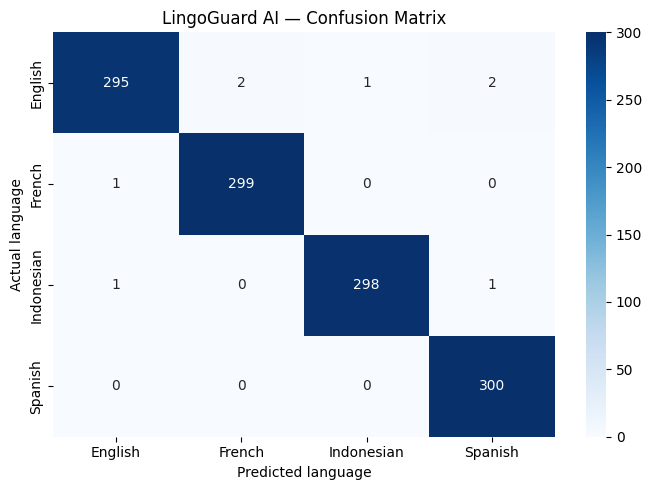

Confusion matrix image saved!


In [99]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["English", "French", "Indonesian", "Spanish"],
    yticklabels=["English", "French", "Indonesian", "Spanish"]
)

plt.xlabel("Predicted language")
plt.ylabel("Actual language")
plt.title("LingoGuard AI — Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "lingoguard_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Confusion matrix image saved!")

In [100]:
import os

files_to_check = [
    "lingoguard_model.joblib",
    "lingoguard_error_analysis.csv",
    "lingoguard_confusion_matrix.png"
]

for filename in files_to_check:
    print(
        filename,
        "— SAVED" if os.path.exists(filename) else "— NOT FOUND"
    )

lingoguard_model.joblib — SAVED
lingoguard_error_analysis.csv — SAVED
lingoguard_confusion_matrix.png — SAVED


In [101]:
import zipfile

files = [
    "lingoguard_model.joblib",
    "lingoguard_error_analysis.csv",
    "lingoguard_confusion_matrix.png"
]

with zipfile.ZipFile(
    "lingoguard_submission_assets.zip", "w"
) as zipf:
    for filename in files:
        zipf.write(filename)

from google.colab import files
files.download("lingoguard_submission_assets.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>